# Bank Customer Churn Prediction - Machine Learning

## 1. Introduction
This notebook develops Machine Learning models to predict whether a bank customer is likely to leave the bank.

## 2. Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest

## 3. Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Define project directory
BASE_DIR = Path.cwd().parent

# Dataset path
DATA_PATH = BASE_DIR / "dataset" / "Churn_Modelling.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display first five records
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (10000, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing Values:
RowNumber          0
Custome

In [4]:
# Separate input features (X) and target variable (y)

X = df.drop(columns=[
    "RowNumber",
    "CustomerId",
    "Surname",
    "Exited"
])

y = df["Exited"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Input Features Shape: (10000, 10)
Target Variable Shape: (10000,)

Target Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Target Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [5]:
# Identify categorical and numerical columns

categorical_features = ["Geography", "Gender"]

numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Geography', 'Gender']

Numerical Features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [6]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 10)
Testing Features: (2000, 10)
Training Target: (8000,)
Testing Target: (2000,)


In [7]:
# Create preprocessing pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)
print("\nPreprocessing completed successfully!")

Training Data Shape: (8000, 13)
Testing Data Shape: (2000, 13)

Preprocessing completed successfully!


In [9]:
# Create Logistic Regression model

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [10]:
# Generate predictions

y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1 Score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

Logistic Regression Results
---------------------------
Accuracy:  0.7135
Precision: 0.3872
Recall:    0.7002
F1 Score:  0.4987
ROC-AUC:   0.7772


In [11]:
# Create Decision Tree model

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [12]:
# Generate predictions

y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1 Score:  {dt_f1:.4f}")
print(f"ROC-AUC:   {dt_roc_auc:.4f}")

Decision Tree Results
---------------------
Accuracy:  0.7420
Precision: 0.4183
Recall:    0.6855
F1 Score:  0.5196
ROC-AUC:   0.7614


In [13]:
# Create Random Forest model

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [14]:
# Generate predictions

y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest Results
---------------------
Accuracy:  0.8510
Precision: 0.6477
Recall:    0.5872
F1 Score:  0.6160
ROC-AUC:   0.8584


In [15]:
# Compare Machine Learning models

ml_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision
    ],
    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall
    ],
    "F1 Score": [
        lr_f1,
        dt_f1,
        rf_f1
    ],
    "ROC-AUC": [
        lr_roc_auc,
        dt_roc_auc,
        rf_roc_auc
    ]
})

ml_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7135,0.3872,0.7002,0.4987,0.7772
1,Decision Tree,0.7420,0.4183,0.6855,0.5196,0.7614
2,Random Forest,0.8510,0.6477,0.5872,0.6160,0.8584


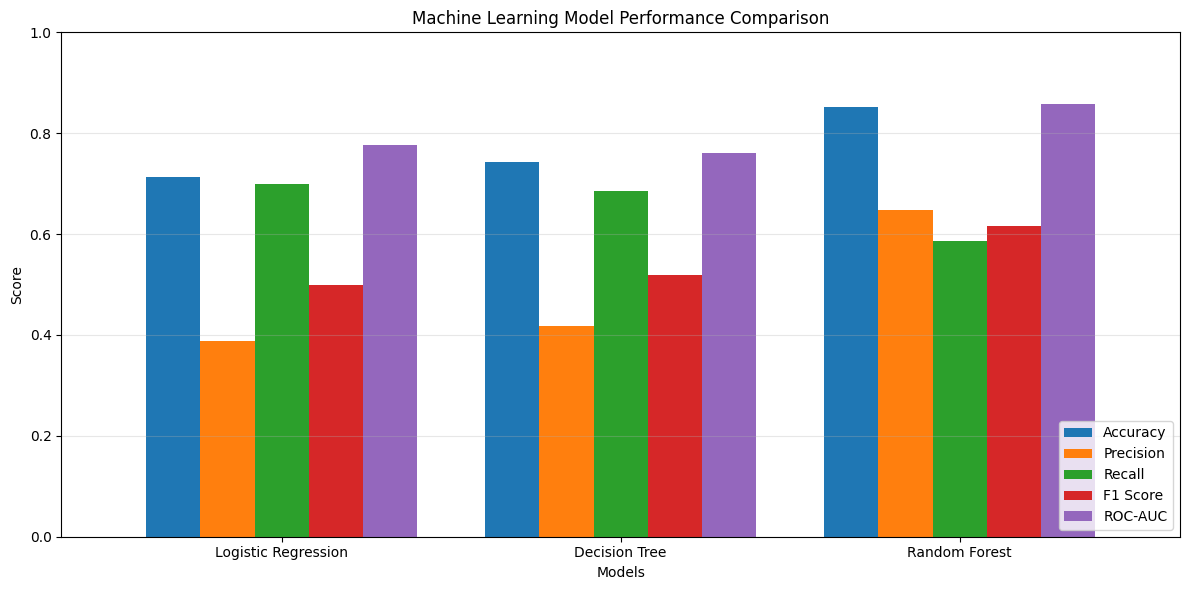

In [16]:
# Visual comparison of ML models

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

ml_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
print("Random Forest Classification Report")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Exited"]
))

Random Forest Classification Report
              precision    recall  f1-score   support

      Stayed       0.90      0.92      0.91      1593
      Exited       0.65      0.59      0.62       407

    accuracy                           0.85      2000
   macro avg       0.77      0.75      0.76      2000
weighted avg       0.85      0.85      0.85      2000



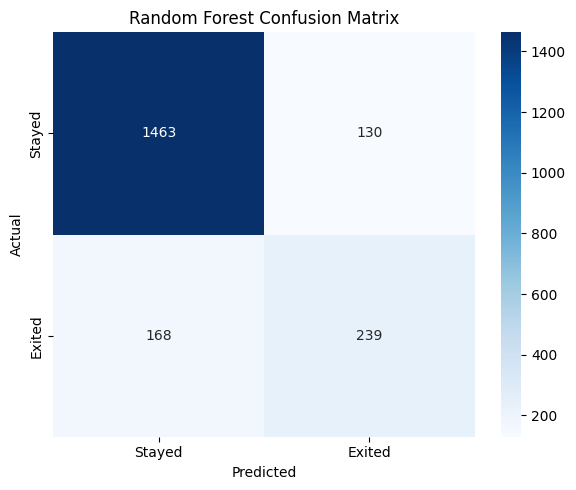

In [18]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [19]:
# Define the models directory

BASE_DIR = Path.cwd().parent
MODEL_DIR = BASE_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained Random Forest pipeline
ML_MODEL_PATH = MODEL_DIR / "bank_churn_pipeline_ml.pkl"

joblib.dump(random_forest_model, ML_MODEL_PATH)

print("Random Forest model saved successfully!")
print("Model location:", ML_MODEL_PATH)

Random Forest model saved successfully!
Model location: c:\Users\navya\Documents\Bank-Customer-Churn\models\bank_churn_pipeline_ml.pkl


In [20]:
# Load the saved model

loaded_ml_model = joblib.load(ML_MODEL_PATH)

# Test prediction using one customer
sample_customer = X_test.iloc[[0]]

prediction = loaded_ml_model.predict(sample_customer)[0]
probability = loaded_ml_model.predict_proba(sample_customer)[0][1]

print("Prediction:", "Exited" if prediction == 1 else "Stayed")
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Stayed
Churn Probability: 9.14 %
